# ScoNet from scratch (Scoliosis1K silhouette PKLs)

This notebook rebuilds ScoNet in **plain PyTorch**. It does not import anything from OpenGait, so there are no repo paths or config parsing to break. Every model piece has its own cell and a tiny shape test.

## The big picture

```
silhouette sequence  [frames, 64, 64]
   -> cut 10px off each side, divide by 255          [frames, 64, 44]
   -> pick 30 random frames                          [30, 64, 44]
   -> ResNet9 on every frame separately              [30, 512, 16, 11]
   -> max over the 30 frames  (temporal pooling)     [512, 16, 11]
   -> split into 16 horizontal strips (HPP)          [512, 16]
   -> one small FC per strip                         [256, 16]   <- "embedding" (used by triplet loss)
   -> BatchNorm + one cosine classifier per strip    [3, 16]     <- "logits"    (used by cross-entropy)
```

## The plan

| Part | What you do | Why |
|---|---|---|
| 1 | Settings | one place for every knob |
| 2 | Look at the data | see what a silhouette sequence is |
| 3 | Preprocessing | same crop and normalisation as `BaseSilCuttingTransform` |
| 4 | Model, piece by piece | each piece tested on its own |
| 5 | Losses | triplet + scaled cross-entropy, as in your YAML |
| 6 | Training loop | SGD, MultiStepLR, exactly the config values |
| 7 | **Sanity check** | 1 sample per class, the model must memorise it |
| 8 | Scale up (optional) | partition JSON, TripletSampler-style batches, evaluation |

Differences from official OpenGait: no multi-GPU or `sync_BN`, and OpenGait's data loader, sampler and trainer are replaced by a few small functions. Mixed precision (`enable_float16`) and checkpoint save / resume are included in Parts 6 and 8.

## What the paper says the pipeline is (arXiv 2407.05726)

| Step | Paper / YAML | Where it is in this notebook |
|---|---|---|
| Data | Scoliosis1K: 1,493 silhouette sequences, about 300 frames each (15 fps), 64x64 cut to 64x44. Classes: negative (Cobb < 10°), neutral (about 10°), positive (> 10°) | Parts 2 and 3 |
| Split | 745 train / 748 test (749 in your file). The **training class ratio is a setting**: positive:neutral:negative = 1:1:2, 1:1:4, **1:1:8 (main result)** or 1:1:16 | Part 8, `PARTITION_JSON` |
| Input | 30 random frames per sequence. A triplet's positive is the **same sequence, different frames** | `random_clip`, `make_triplet_batch_fn` |
| Model | ResNet-style backbone, temporal max pooling, horizontal pooling (16 strips, max + mean), FC, BNNeck, cross-entropy. **ScoNet** = this alone | Part 4 |
| Multi-task | **ScoNet-MT** adds a triplet loss on subject identity (gait recognition), margin 0.2. Total loss = cross-entropy + triplet. This is also what the official YAML and `sconet.py` train (triplet on `pids`, cross-entropy on the class) | Part 5, `MODEL_VARIANT` |
| Training | SGD, lr 0.1, weight decay 5e-4, lr divided by 10 at 10k / 14k / 18k, 20,000 iterations, batch 8 identities x 8 sequences | Part 6 and 8, `PROFILE` |
| Test | Whole sequence (the first 720 frames at most), accuracy. OpenGait's `evaluate_scoliosis` also logs macro precision / recall / F1; the paper's table adds sensitivity and specificity | `evaluate` |

**What to expect (split 1:1:8, 20,000 iterations):** ScoNet 51.3% accuracy, ScoNet-MT 82.0%. On 1:1:16 (your YAML's file): ScoNet 23.7%, ScoNet-MT 49.5%. The paper itself says plain ScoNet is vulnerable to class imbalance, which is why it predicts mostly negative. A model trained for only a few hundred iterations should not be compared with these numbers.

## 1. Settings
Edit `DATASET_ROOT` so it points at the folder that **directly contains** the subject folders (`00000`, `00001`, ...).

The seed is fixed (`SEED = 0`), so the weight initialisation, the batches and the random frames are the same on every run. `set_seed()` is called again right before each model is built, so a result never depends on which cells you ran before. (GPU results can still differ in the last decimals between machines.)

In [1]:
import copy, json, pickle, random, time
from functools import lru_cache
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ---- EDIT THIS ----
DATASET_ROOT = Path(r"C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K-sil-pkl\Scoliosis1K-sil-pkl")
# On Windows you can write: Path(r"C:\Users\you\...\Scoliosis1K-sil-pkl")

# ---- values taken from your YAML ----
LABELS = ["negative", "neutral", "positive"]      # class id = position in this list
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
N_FRAMES = 30          # trainer_cfg.sampler.frames_num_fixed
NUM_PARTS = 16         # bin_num
NUM_CLASSES = 3
CE_SCALE = 16          # CrossEntropyLoss scale
TRIPLET_MARGIN = 0.2

# Fixed seed: same weight initialisation, same batches, same random frames on every run.
SEED = 0

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                   # also seeds the GPU

set_seed()
torch.backends.cudnn.deterministic = True     # always pick the same GPU kernels
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f"DATASET_ROOT not found: {DATASET_ROOT.resolve()}\n"
        f"Current working folder: {Path.cwd()}\n"
        "Edit DATASET_ROOT above so it points at the folder that contains the subject folders."
    )
print("Device :", DEVICE, "| PyTorch", torch.__version__)
print("Dataset:", DATASET_ROOT.resolve())

Device : cuda | PyTorch 2.6.0+cu124
Dataset: C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K-sil-pkl\Scoliosis1K-sil-pkl


## 2. Look at the data

Expected layout: `<subject>/<class folder>/<view>/<file>.pkl`, where the class folder is Negative / Neutral / Positive. Each pkl is one silhouette video: a uint8 array `[frames, 64, 64]` with values 0 to 255.

The next cell grabs the first pkl of each class.

In [2]:
def find_one_sample_per_class(root):
    """Return {class_name: path_to_pkl} using the first pkl found for each class."""
    found = {}
    for pkl in root.rglob("*.pkl"):
        for folder in pkl.relative_to(root).parts[:-1]:
            name = folder.lower()
            if name in LABEL_TO_ID and name not in found:
                found[name] = pkl
        if len(found) == len(LABELS):
            break
    return found

def load_pkl(path):
    """Load one silhouette sequence as a uint8 array [T, H, W]."""
    with open(path, "rb") as f:
        seq = np.asarray(pickle.load(f))
    if seq.ndim == 4 and seq.shape[1] == 1:       # [T,1,H,W] -> [T,H,W]
        seq = seq[:, 0]
    elif seq.ndim == 4 and seq.shape[-1] == 1:    # [T,H,W,1] -> [T,H,W]
        seq = seq[..., 0]
    if seq.ndim != 3 or len(seq) == 0:
        raise ValueError(f"Expected a non-empty [T,H,W] array, got {seq.shape} from {path}")
    return seq

sample_paths = find_one_sample_per_class(DATASET_ROOT)
missing = [name for name in LABELS if name not in sample_paths]
if missing:
    raise FileNotFoundError(f"No pkl found for class(es) {missing} under {DATASET_ROOT}")

raw = {}    # class name -> uint8 array [T, H, W]
for name in LABELS:
    raw[name] = load_pkl(sample_paths[name])
    seq = raw[name]
    print(f"{name:9s} {str(sample_paths[name].relative_to(DATASET_ROOT)):45s} "
          f"shape={seq.shape} dtype={seq.dtype} range={seq.min()}..{seq.max()}")

negative  00493\negative\000_180\000_180.pkl            shape=(300, 64, 64) dtype=uint8 range=0..255
neutral   01293\neutral\000_180\000_180.pkl             shape=(300, 64, 64) dtype=uint8 range=0..255
positive  00000\positive\000_180\000_180.pkl            shape=(300, 64, 64) dtype=uint8 range=0..255


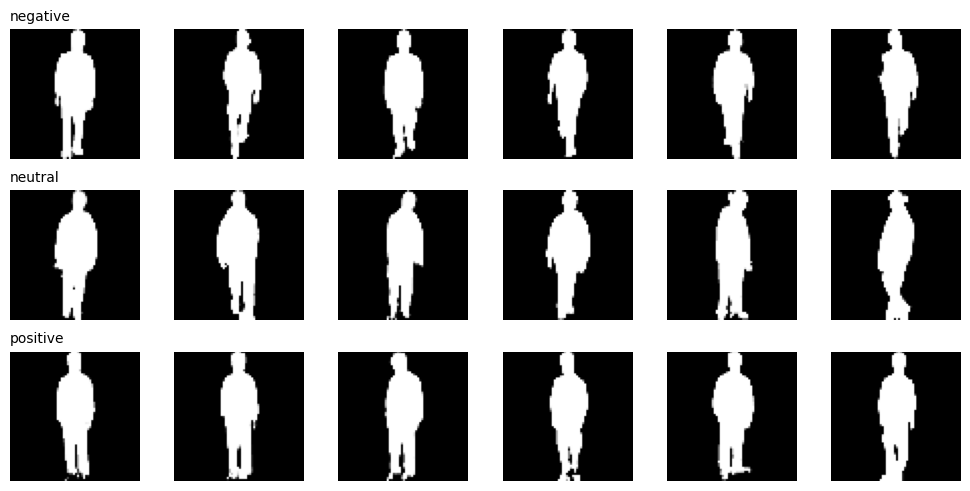

In [3]:
# A quick look: 6 evenly spaced frames from each sample
fig, axes = plt.subplots(len(LABELS), 6, figsize=(10, 5))
for row, name in enumerate(LABELS):
    seq = raw[name]
    for col, t in enumerate(np.linspace(0, len(seq) - 1, 6).round().astype(int)):
        axes[row, col].imshow(seq[t], cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Preprocessing

Two tiny functions:

- `cut_and_normalize` copies `BaseSilCuttingTransform`: a 64 px wide image loses 10 px on each side (so 64 to 44 wide), then values are divided by 255.
- `random_clip` picks `N_FRAMES` random frames from a sequence. Training uses this (`fixed_unordered` in your YAML). Frame order does not matter because temporal pooling is a max.

In [4]:
def cut_and_normalize(seq):
    """uint8 [T, H, W]  ->  float32 [T, H, W-20] in 0..1  (same as BaseSilCuttingTransform)."""
    cut = seq.shape[-1] // 64 * 10
    if cut > 0:
        seq = seq[..., cut:-cut]
    return seq.astype(np.float32) / 255.0

def random_clip(seq, n_frames=N_FRAMES):
    """Pick n_frames random frames (with repeats only if the video is shorter)."""
    idx = np.random.choice(len(seq), n_frames, replace=len(seq) < n_frames)
    return seq[idx]

def train_clip(seq, n_frames=N_FRAMES):
    return cut_and_normalize(random_clip(seq, n_frames))

clip = cut_and_normalize(random_clip(raw["positive"]))
print("clip shape:", clip.shape, "| range:", clip.min(), "to", clip.max())
assert clip.shape == (N_FRAMES, 64, 44)

clip shape: (30, 64, 44) | range: 0.0 to 1.0


## 4. The model, one piece at a time

Naming used in the shape comments: `n` = batch (sequences), `s` = frames, `c` = channels, `h, w` = image size, `p` = parts (16).

### 4.1 Backbone: ResNet9
Four stages, one `BasicBlock` each (channels 64, 128, 256, 512 and strides 1, 2, 2, 1, no max-pool). A 64x44 image becomes a 512-channel 16x11 feature map.

In [5]:
class BasicBlock(nn.Module):
    """conv-bn-relu-conv-bn, plus a skip connection."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:        # skip path must match the new shape
            self.downsample = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)

class ResNet9(nn.Module):
    def __init__(self, in_channels=1, channels=(64, 128, 256, 512), strides=(1, 2, 2, 1)):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, channels[0], 3, 1, 1, bias=False),
            nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        blocks, prev = [], channels[0]
        for ch, stride in zip(channels, strides):
            blocks.append(BasicBlock(prev, ch, stride))
            prev = ch
        self.blocks = nn.Sequential(*blocks)

    def forward(self, x):              # [n, 1, h, w] -> [n, 512, h/4, w/4]
        return self.blocks(self.stem(x))

# test: 5 images of 64x44
print(ResNet9()(torch.randn(5, 1, 64, 44)).shape)   # expect [5, 512, 16, 11]

torch.Size([5, 512, 16, 11])


### 4.2 Run the backbone on every frame
ResNet9 expects ordinary images `[batch, 1, h, w]`, but we have videos `[n, 1, s, h, w]`. `FrameWise` folds the frames into the batch dimension, runs the backbone, and unfolds again.

In [6]:
class FrameWise(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net

    def forward(self, x):                                   # x: [n, c, s, h, w]
        n, c, s, h, w = x.shape
        x = x.permute(0, 2, 1, 3, 4).reshape(n * s, c, h, w)    # every frame becomes its own image
        out = self.net(x)                                       # [n*s, c', h', w']
        _, c2, h2, w2 = out.shape
        return out.reshape(n, s, c2, h2, w2).permute(0, 2, 1, 3, 4)   # [n, c', s, h', w']

test = FrameWise(ResNet9())(torch.randn(2, 1, 7, 64, 44))
print(test.shape)   # expect [2, 512, 7, 16, 11]

torch.Size([2, 512, 7, 16, 11])


### 4.3 Horizontal pooling (HPP)
After the temporal max we have `[n, 512, 16, 11]`. HPP cuts the image into 16 horizontal strips (here exactly one row each) and summarises each strip as `mean + max`. Each strip then has its own classifier, so different body regions (shoulders, waist, ...) can specialise.

In [7]:
class HorizontalPooling(nn.Module):
    def __init__(self, num_parts=16):
        super().__init__()
        self.num_parts = num_parts

    def forward(self, x):                                   # x: [n, c, h, w]
        n, c = x.shape[:2]
        x = x.reshape(n, c, self.num_parts, -1)             # [n, c, p, strip_pixels]
        return x.mean(-1) + x.max(-1)[0]                    # [n, c, p]

print(HorizontalPooling(16)(torch.randn(2, 512, 16, 11)).shape)   # expect [2, 512, 16]

torch.Size([2, 512, 16])


### 4.4 SeparateFCs and SeparateBNNecks
"Separate" means each of the 16 parts has its **own** weights, stored as a `[parts, in, out]` tensor and applied with one batched matrix multiply.

- `SeparateFCs`: 512 to 256 per part. Its output is the **embedding** (triplet loss).
- `SeparateBNNecks`: BatchNorm, then a cosine classifier per part (256 to 3). Its output is the **logits** (cross-entropy). Features and class weights are L2-normalised, so each logit is a cosine similarity in [-1, 1], which is why the CE loss multiplies by a scale of 16.

In [8]:
class SeparateFCs(nn.Module):
    def __init__(self, parts, in_ch, out_ch):
        super().__init__()
        self.weight = nn.Parameter(nn.init.xavier_uniform_(torch.empty(parts, in_ch, out_ch)))

    def forward(self, x):                                   # x: [n, c, p]
        x = x.permute(2, 0, 1)                              # [p, n, c]
        return x.matmul(self.weight).permute(1, 2, 0)       # [p, n, out] -> [n, out, p]

class SeparateBNNecks(nn.Module):
    def __init__(self, parts, in_ch, num_classes):
        super().__init__()
        self.bn = nn.BatchNorm1d(in_ch * parts)
        self.weight = nn.Parameter(nn.init.xavier_uniform_(torch.empty(parts, in_ch, num_classes)))

    def forward(self, x):                                   # x: [n, c, p]
        n, c, p = x.shape
        x = self.bn(x.reshape(n, c * p)).reshape(n, c, p)
        feat = F.normalize(x.permute(2, 0, 1), dim=-1)      # [p, n, c], unit length
        w = F.normalize(self.weight, dim=1)                 # [p, c, classes], unit length per class
        logits = feat.matmul(w)                             # [p, n, classes]  (cosine similarity)
        return x, logits.permute(1, 2, 0)                   # features [n, c, p], logits [n, classes, p]

e = SeparateFCs(16, 512, 256)(torch.randn(4, 512, 16))
f, l = SeparateBNNecks(16, 256, 3)(e)
print(e.shape, f.shape, l.shape)    # expect [4,256,16] [4,256,16] [4,3,16]

torch.Size([4, 256, 16]) torch.Size([4, 256, 16]) torch.Size([4, 3, 16])


### 4.5 Put it together: ScoNet

In [9]:
class ScoNet(nn.Module):
    def __init__(self, num_parts=NUM_PARTS, num_classes=NUM_CLASSES):
        super().__init__()
        self.backbone = FrameWise(ResNet9())
        self.hpp = HorizontalPooling(num_parts)
        self.fcs = SeparateFCs(num_parts, 512, 256)
        self.bnnecks = SeparateBNNecks(num_parts, 256, num_classes)

    def forward(self, sils):                 # sils: [n, s, h, w]  (silhouettes, 0..1)
        x = sils.unsqueeze(1)                # [n, 1, s, h, w]  add the channel dimension
        x = self.backbone(x)                 # [n, 512, s, 16, 11]
        x = x.max(dim=2)[0]                  # [n, 512, 16, 11]  temporal pooling: max over frames
        x = self.hpp(x)                      # [n, 512, 16]
        embed = self.fcs(x)                  # [n, 256, 16]
        _, logits = self.bnnecks(embed)      # [n, 3, 16]
        return embed, logits

def init_weights(m):
    """Same initialisation idea as OpenGait's init_parameters."""
    if isinstance(m, nn.Conv2d):
        nn.init.xavier_uniform_(m.weight)
    elif isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)) and m.affine:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

def make_model():
    model = ScoNet()
    model.apply(init_weights)
    return model.to(DEVICE)

model = make_model()
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

with torch.no_grad():
    embed, logits = model.eval()(torch.rand(2, N_FRAMES, 64, 44, device=DEVICE))
print("embed :", tuple(embed.shape), " expect (2, 256, 16)")
print("logits:", tuple(logits.shape), " expect (2, 3, 16)")
assert embed.shape == (2, 256, 16) and logits.shape == (2, 3, 16)

Parameters: 7.01M
embed : (2, 256, 16)  expect (2, 256, 16)
logits: (2, 3, 16)  expect (2, 3, 16)


## 5. Losses

Total loss = `triplet + cross-entropy` (both weight 1.0 in your YAML).

- **Triplet loss** works on the 256-d embeddings. It pulls clips with the **same subject id** together and pushes different ids apart by at least `margin = 0.2`. Same convention as your ScoNet file (`'labels': pids`). It needs at least two clips per id in the batch, which is what the TripletSampler guarantees.
- **Cross-entropy** works on the logits and uses the class (negative / neutral / positive), with scale 16 and label smoothing 0.1 (OpenGait's defaults in `ce.py`). Every one of the 16 parts has to predict the right class.

In [10]:
def pairwise_distance(x):
    """x: [p, n, c] -> Euclidean distance between every pair of clips, for each part: [p, n, n]."""
    sq = torch.sum(x ** 2, dim=-1)                                       # [p, n]
    d2 = sq.unsqueeze(2) + sq.unsqueeze(1) - 2 * x.matmul(x.transpose(1, 2))
    return torch.sqrt(F.relu(d2))

def triplet_loss(embed, ids, margin=TRIPLET_MARGIN):
    """embed: [n, c, p]   ids: [n] subject ids.  Returns a scalar (same maths as OpenGait's TripletLoss)."""
    x = embed.permute(2, 0, 1).contiguous().float()                      # [p, n, c]
    dist = pairwise_distance(x)                                          # [p, n, n]
    p, n, _ = dist.shape

    same = ids.unsqueeze(1) == ids.unsqueeze(0)                          # [n, n] True where two clips share a subject id
    ap_dist = dist[:, same].view(p, n, -1, 1)                            # anchor-positive distances (the anchor counts as its own positive)
    an_dist = dist[:, ~same].view(p, n, 1, -1)                           # anchor-negative distances

    # every (anchor, positive, negative) combination: max(0, d(a,p) - d(a,n) + margin)
    loss = F.relu(ap_dist - an_dist + margin).reshape(p, -1)             # [p, num_triplets]

    # average over the triplets that still violate the margin, separately for each part
    num_active = (loss != 0).sum(dim=-1).float()                         # [p]
    loss_per_part = loss.sum(dim=-1) / (num_active + 1e-9)
    loss_per_part[num_active == 0] = 0
    return loss_per_part.mean()

def scaled_ce_loss(logits, classes, scale=CE_SCALE, label_smoothing=0.0):
    """logits: [n, k, p]   classes: [n].  Cross-entropy for every part, averaged."""
    n, k, p = logits.shape
    target = classes.unsqueeze(1).expand(n, p)                     # same class label for all 16 parts
    return F.cross_entropy(logits * scale, target, label_smoothing=label_smoothing)

# test with random data: 2 subjects x 3 clips each
t = triplet_loss(torch.randn(6, 256, 16), torch.tensor([0, 0, 0, 1, 1, 1]))
c = scaled_ce_loss(torch.randn(6, 3, 16), torch.tensor([0, 0, 0, 1, 1, 2]))
print("triplet:", float(t), "| ce:", float(c))

triplet: 1.0707190036773682 | ce: 11.729720115661621


## 6. Training loop

One iteration: get a batch, forward, compute both losses, backward, SGD step. Optimizer settings come from your YAML: SGD, lr 0.1, momentum 0.9, weight decay 5e-4, learning rate multiplied by 0.1 at each milestone.

`get_batch()` can be any function that returns `(silhouettes [n,s,h,w], subject_ids [n], class_ids [n])`. The sanity check and the full run below just plug in different batch functions.

In [11]:
def compute_loss(embed, logits, ids, classes, triplet_on, label_smoothing):
    """Total loss = cross-entropy (+ triplet).  Returns (total, cross-entropy, triplet)."""
    loss_ce = scaled_ce_loss(logits, classes, label_smoothing=label_smoothing)
    if triplet_on is None:                                          # plain ScoNet: no triplet term
        return loss_ce, loss_ce, torch.zeros((), device=DEVICE)
    loss_tri = triplet_loss(embed, ids if triplet_on == "identity" else classes)
    return loss_ce + loss_tri, loss_ce, loss_tri

def save_checkpoint(path, model, optimizer, scheduler, scaler, it, history):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "iter": it, "history": history}, path)

def load_checkpoint(path, model, optimizer, scheduler, scaler):
    """Restore what save_checkpoint stored.  Returns (history, next iteration)."""
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    scaler.load_state_dict(ckpt["scaler"])
    print(f"resumed from {path} at iteration {ckpt['iter']}")
    return ckpt["history"], ckpt["iter"] + 1

def train(model, get_batch, iters, lr=0.1, milestones=(), log_every=10,
          triplet_on="identity", amp=False, label_smoothing=0.0,
          ckpt_path=None, save_every=0, resume=False):
    """
    triplet_on: "identity" -> CE + triplet on subject ids   (ScoNet-MT, the YAML / paper's best model)
                "class"    -> CE + triplet on class labels  (ScoNet-Triplet, my reading of Table 3)
                None       -> cross-entropy only            (plain ScoNet)
    amp: float16 mixed precision (YAML: enable_float16 = true). Only used on CUDA.
    """
    amp = amp and DEVICE.type == "cuda"
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(milestones), gamma=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    history = {"triplet": [], "ce": [], "acc": []}
    start_it = 1

    if resume and ckpt_path and Path(ckpt_path).is_file():
        history, start_it = load_checkpoint(ckpt_path, model, optimizer, scheduler, scaler)

    t0 = time.time()
    for it in range(start_it, iters + 1):
        model.train()
        sils, ids, classes = get_batch()
        sils = torch.as_tensor(sils, dtype=torch.float32, device=DEVICE)
        ids = torch.as_tensor(ids, dtype=torch.long, device=DEVICE)
        classes = torch.as_tensor(classes, dtype=torch.long, device=DEVICE)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
            embed, logits = model(sils)
        embed, logits = embed.float(), logits.float()                # losses are computed in float32

        loss, loss_ce, loss_tri = compute_loss(embed, logits, ids, classes, triplet_on, label_smoothing)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        acc = (logits.mean(-1).argmax(1) == classes).float().mean().item()   # average the 16 parts, then argmax
        history["triplet"].append(loss_tri.item())
        history["ce"].append(loss_ce.item())
        history["acc"].append(acc)

        if it == start_it or it % log_every == 0:
            elapsed = time.time() - t0
            eta = elapsed / (it - start_it + 1) * (iters - it)
            print(f"iter {it:5d} | triplet {loss_tri.item():.4f} | ce {loss_ce.item():.4f} | acc {acc:.2f}"
                  f" | {elapsed / 60:6.1f} min elapsed, ETA {eta / 60:6.1f} min")
        if ckpt_path and save_every and (it % save_every == 0 or it == iters):
            save_checkpoint(ckpt_path, model, optimizer, scheduler, scaler, it, history)
    return history

def plot_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(history["triplet"], label="triplet"); ax[0].plot(history["ce"], label="cross-entropy")
    ax[0].set_xlabel("iteration"); ax[0].set_title("loss"); ax[0].legend()
    ax[1].plot(history["acc"]); ax[1].set_xlabel("iteration"); ax[1].set_title("train accuracy"); ax[1].set_ylim(0, 1.05)
    plt.tight_layout(); plt.show()

For evaluation we use the **whole** sequence (the first 720 frames at most, like `frames_all_limit` in your YAML and OpenGait's `collate_fn.py`). The model returns logits `[1, 3, 16]`; averaging over the 16 parts gives one score per class, and the biggest score is the prediction.

In [12]:
@torch.no_grad()
def predict(model, seq_uint8, max_frames=720):
    """One raw sequence [T, 64, 64] -> (predicted class id, class probabilities)."""
    model.eval()
    seq_uint8 = seq_uint8[:max_frames]       # OpenGait (collate_fn.py) keeps the first frames_all_limit frames
    x = torch.from_numpy(cut_and_normalize(seq_uint8)).unsqueeze(0).to(DEVICE)    # [1, T, 64, 44]
    _, logits = model(x)                                                           # [1, 3, 16]
    scores = logits.mean(-1)                                                       # [1, 3]
    probs = torch.softmax(scores * CE_SCALE, dim=-1)[0].cpu().numpy()
    return int(probs.argmax()), probs

## 7. Sanity check: 1 sample per class

**Goal:** show the code works end to end. With only three videos the model must be able to memorise them. If it cannot, something is broken.

**Trick:** the triplet loss needs several clips per subject. We have only one video per class, so each batch cuts **K different random 30-frame clips** out of every video and treats the clips of one video as the same "subject". With 3 videos and K clips each, a batch has 3K sequences.

If you hit an out-of-memory error, lower `K_CLIPS` or `SANITY_FRAMES`. On CPU the notebook automatically uses a smaller setup so it finishes.

In [13]:
if DEVICE.type == "cuda":
    SANITY_FRAMES, K_CLIPS, SANITY_ITERS, EVAL_MAX_FRAMES = N_FRAMES, 2, 20, 60 #Original sanity test: N_FRAMES, 4, 100, 720
else:                                   # CPU: smaller and slower-to-fail setup
    SANITY_FRAMES, K_CLIPS, SANITY_ITERS, EVAL_MAX_FRAMES = 8, 2, 60, 100
SANITY_LR = 0.1                         # lower to 0.01 if the loss jumps around

def get_sanity_batch():
    clips, ids, classes = [], [], []
    for class_id, name in enumerate(LABELS):
        for _ in range(K_CLIPS):
            clips.append(train_clip(raw[name], SANITY_FRAMES))
            ids.append(class_id)          # one video per class -> its id is just the class number
            classes.append(class_id)
    return np.stack(clips), np.array(ids), np.array(classes)

sils, ids, classes = get_sanity_batch()
print("batch silhouettes:", sils.shape, "| ids:", ids, "| classes:", classes)

batch silhouettes: (6, 30, 64, 44) | ids: [0 0 1 1 2 2] | classes: [0 0 1 1 2 2]


iter     1 | triplet 0.1210 | ce 1.3019 | acc 0.33 |    0.0 min elapsed, ETA    0.4 min
iter    10 | triplet 0.3087 | ce 0.0098 | acc 1.00 |    0.1 min elapsed, ETA    0.1 min
iter    20 | triplet 0.2025 | ce 0.0496 | acc 1.00 |    0.1 min elapsed, ETA    0.0 min


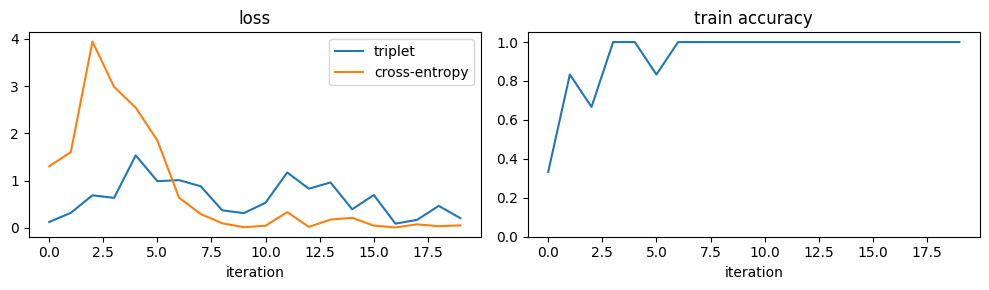

In [14]:
set_seed()                                  # same start every time
sanity_model = make_model()
history = train(sanity_model, get_sanity_batch, iters=SANITY_ITERS, lr=SANITY_LR, log_every=10)
plot_history(history)

In [15]:
ce_start, ce_end = np.mean(history["ce"][:3]), np.mean(history["ce"][-5:])
acc_end = np.mean(history["acc"][-5:])
print(f"cross-entropy: {ce_start:.3f} -> {ce_end:.3f}")
print(f"train accuracy (last 5 iters): {acc_end:.2f}")
print("TRAINING CHECK:", "PASS" if (ce_end < 0.5 * ce_start and acc_end >= 0.99) else "FAIL - see notes below")

cross-entropy: 2.282 -> 0.040
train accuracy (last 5 iters): 1.00
TRAINING CHECK: PASS


Now the evaluation path: whole video in, prediction out. The same three videos are used, so this only proves the eval code works.

In [16]:
correct = 0
for class_id, name in enumerate(LABELS):
    pred, probs = predict(sanity_model, raw[name], EVAL_MAX_FRAMES)
    correct += int(pred == class_id)
    print(f"true {name:9s} -> predicted {LABELS[pred]:9s} probs (neg, neu, pos) = {np.round(probs, 3)}")
print(f"\nEVAL CHECK: {correct}/3 correct")

true negative  -> predicted neutral   probs (neg, neu, pos) = [0.    0.997 0.002]
true neutral   -> predicted neutral   probs (neg, neu, pos) = [0.    0.997 0.002]
true positive  -> predicted neutral   probs (neg, neu, pos) = [0.    0.997 0.003]

EVAL CHECK: 1/3 correct


## 8. Train and evaluate with the paper's protocol

Same model and `train()` as before. This part now follows the paper (see the table at the top of the notebook):

- **Split.** `PARTITION_JSON` decides the training class ratio. `Scoliosis1K_118.json` is the paper's main setting (1:1:8). `Scoliosis1K_1116.json`, the file in your YAML, is the hardest one (1:1:16). The cell prints your class counts next to the paper's.
- **`MODEL_VARIANT`** picks the model from the paper's ablations: plain **ScoNet** (cross-entropy only), **ScoNet-Triplet**, or **ScoNet-MT** (cross-entropy + triplet on identity, the model your ScoNet file builds).
- **`PROFILE`** picks the training budget: `quick` (200 iterations, a pipeline check), `scaled` (2000), or `paper` (20000 iterations, 8 x 8 batch, learning rate divided by 10 at 50%, 70% and 90%).
- **Output.** Confusion matrix, accuracy, sensitivity and specificity as the paper reports them, the macro precision / recall / F1 that OpenGait's `evaluate_scoliosis` logs, and the paper's numbers for the same split to compare against.

Watch the ETA printed during training. Stop the kernel if it is too slow; set `RESUME = True` later to continue from the last checkpoint.

In [17]:
# ================= protocol settings =================
RUN_FULL = True
PARTITION_JSON = Path(r"c:/Users/arina/OneDrive/Documents/Reproduce_Paper/OpenGait/datasets/Scoliosis1K/Scoliosis1K_118.json")   # 118 = train ratio 1:1:8 (paper's main setting). 1116 = 1:1:16
ONE_PER_CLASS = True       # True = train on only the first sequence of each class (3 videos in total, like the Part 7 sanity check) | False = the whole training split

MODEL_VARIANT = "ScoNet-Triplet"   # "ScoNet" = CE only (paper's plain ScoNet) | "ScoNet-Triplet" = CE + triplet on class | "ScoNet-MT" = CE + triplet on identity (= what the official YAML / sconet.py trains)
PROFILE = "test"             # "quick" (200 iterations, 4x4) | "scaled" (2000, 8x4) | "paper" (20000, 8x8)
PROFILES = {                  # iterations, identities per batch, clips per identity
    "quick":  dict(iters=200,   ids=4, seqs=4),    # pipeline check only (what you ran before)
    "scaled": dict(iters=2000,  ids=8, seqs=4),    # 10% of the iterations, half the batch
    "paper":  dict(iters=20000, ids=8, seqs=8),
    "test" : dict(iters=5000, ids=4, seqs=4), 
}
TOTAL_ITERS = PROFILES[PROFILE]["iters"]
IDS_PER_BATCH = PROFILES[PROFILE]["ids"]
SEQS_PER_ID = PROFILES[PROFILE]["seqs"]
FULL_EVAL_FRAMES = 720        # YAML: frames_all_limit

TRIPLET_ON = {"ScoNet": None, "ScoNet-Triplet": "class", "ScoNet-MT": "identity"}   # which triplet loss each variant uses

USE_AMP = DEVICE.type == "cuda"   # YAML: enable_float16 = true
LABEL_SMOOTHING = 0.1             # OpenGait's CrossEntropyLoss default (label_smooth=True, eps=0.1, checked in ce.py; the YAML does not override it); 0.0 = off
LOG_EVERY = 20 if TOTAL_ITERS <= 2000 else 100
SAVE_EVERY = 500                  # checkpoint every N iterations (and at the end)
RESUME = False                    # True = continue from CKPT_PATH if it exists
CKPT_PATH = f"sconet_{MODEL_VARIANT}_{PROFILE}{'_one_per_class' if ONE_PER_CLASS else ''}.pt"

EVAL_EVERY = max(TOTAL_ITERS // 4, 1)     # test a small subset 4 times while training; 0 = only at the end
EVAL_PER_CLASS = 30                       # test videos per class in that subset

# ================= numbers from the paper (arXiv 2407.05726) =================
SPLIT_KEY = PARTITION_JSON.stem.split("_")[-1]                                     # "118", "1116", ...
PAPER_SPLITS = {"112": (186, 186, 373), "114": (124, 124, 497),
                "118": (74, 74, 596), "1116": (41, 41, 663)}                       # TRAIN counts: (positive, neutral, negative)
PAPER_ACC = {"112": (91.4, 95.2), "114": (88.6, 90.5),
             "118": (51.3, 82.0), "1116": (23.7, 49.5)}                            # Table 4 accuracy: (ScoNet, ScoNet-MT)
PAPER_TABLE2 = {"ScoNet": (51.3, 100.0, 33.2), "ScoNet-MT": (82.0, 99.0, 76.5)}  # accuracy, sensitivity, specificity (split 118)
# Fig. 4, ScoNet-MT on split 118, rows = true, cols = predicted, order = negative, neutral, positive
PAPER_FIG4_MT = np.array([[202, 2, 0], [69, 55, 2], [59, 3, 357]])

In [18]:
@lru_cache(maxsize=None)
def load_pkl_cached(path):
    """Load each pkl only once (the same videos are used again and again)."""
    return load_pkl(path)

def build_index(root, subject_ids):
    """List (subject_id, class_id, pkl_path) for every sequence of the given subjects."""
    items, missing = [], 0
    for sid in subject_ids:
        folder = root / str(sid)
        if not folder.is_dir():
            missing += 1
            continue
        for pkl in sorted(folder.rglob("*.pkl")):
            names = [p.lower() for p in pkl.relative_to(root).parts[:-1]]
            class_id = next((LABEL_TO_ID[n] for n in names if n in LABEL_TO_ID), None)
            if class_id is not None:
                items.append((str(sid), class_id, pkl))
    print(f"{len(items)} sequences from {len(set(i[0] for i in items))} subjects ({missing} listed subjects not on disk)")
    return items

def make_triplet_batch_fn(items, ids_per_batch, seqs_per_id):
    """Batches like OpenGait's TripletSampler (checked in sampler.py): `ids_per_batch` random subjects without replacement,
    `seqs_per_id` sequences of each (repeated only if the subject has fewer)."""
    by_subject = {}
    for sid, class_id, path in items:
        by_subject.setdefault(sid, []).append((class_id, path))
    subjects = list(by_subject)
    index = {sid: i for i, sid in enumerate(subjects)}          # subject id (string) -> integer id for the loss

    def get_batch():
        clips, ids, classes = [], [], []
        for sid in random.sample(subjects, min(ids_per_batch, len(subjects))):
            pool = by_subject[sid]
            if len(pool) >= seqs_per_id:
                picks = random.sample(pool, seqs_per_id)        # different sequences of this subject
            else:
                picks = random.choices(pool, k=seqs_per_id)     # too few sequences: repeat (new random frames each time)
            for class_id, path in picks:
                clips.append(train_clip(load_pkl_cached(path)))
                ids.append(index[sid])
                classes.append(class_id)
        return np.stack(clips), np.array(ids), np.array(classes)
    return get_batch

def class_counts(items):
    counts = [0, 0, 0]                       # negative, neutral, positive
    for _, class_id, _ in items:
        counts[class_id] += 1
    return counts

def select_one_per_class(items):
    """Keep only the first sequence of each class (negative, neutral, positive) -> 3 sequences. Fixed: no randomness involved."""
    selected = {}
    for item in items:
        _, class_id, _ = item
        if class_id not in selected:
            selected[class_id] = item
    return [selected[c] for c in sorted(selected)]

def check_split(train_items, test_items):
    """Print the class counts next to the paper's, to confirm the partition is the one you meant."""
    tr, te = class_counts(train_items), class_counts(test_items)
    total = max(sum(tr), 1)
    pos = max(tr[2], 1)
    print(f"train: negative {tr[0]} | neutral {tr[1]} | positive {tr[2]}   (positive:neutral:negative = 1:{tr[1] / pos:.1f}:{tr[0] / pos:.1f})")
    print(f"test : negative {te[0]} | neutral {te[1]} | positive {te[2]}")
    if SPLIT_KEY in PAPER_SPLITS:
        p, n, g = PAPER_SPLITS[SPLIT_KEY]
        print(f"paper, split {SPLIT_KEY}: train positive {p} | neutral {n} | negative {g}")
    p_pos = tr[2] / total
    print(f"negative is {tr[0] / total:.0%} of the training set; a batch of {IDS_PER_BATCH} identities "
          f"contains no positive in {(1 - p_pos) ** IDS_PER_BATCH:.0%} of iterations")

def make_eval_subset(test_items, per_class=EVAL_PER_CLASS):
    """A small test subset used for the quick checks during training. Always the same videos (own seed 0)."""
    rng = random.Random(0)
    subset = []
    for c in range(3):
        pool = [it for it in test_items if it[1] == c]
        subset += rng.sample(pool, min(per_class, len(pool)))
    return subset

In [19]:
def confusion(model, items, max_frames=FULL_EVAL_FRAMES):
    """rows = true, cols = predicted (negative, neutral, positive); the whole video (up to max_frames) per sequence."""
    conf = np.zeros((3, 3), dtype=int)
    for _, class_id, path in items:
        pred, _ = predict(model, load_pkl_cached(path), max_frames)
        conf[class_id, pred] += 1
    return conf

def paper_metrics(conf):
    """accuracy, sensitivity, specificity as the numbers in the paper's Table 2 and Fig. 4 work out.
    Derived from Fig. 4: the paper's text definitions look swapped, and OpenGait's evaluate_scoliosis does not
    compute sensitivity / specificity at all (it logs accuracy and the macro precision / recall / F1, see macro_metrics)."""
    accuracy = conf.trace() / max(conf.sum(), 1)
    sensitivity = conf[0, 0] / max(conf[0].sum(), 1)                 # negatives predicted negative
    specificity = conf[1:, 1:].sum() / max(conf[1:].sum(), 1)        # neutral + positive predicted as neutral or positive
    return accuracy, sensitivity, specificity

def macro_metrics(conf):
    """Macro-averaged precision, recall and F1, as OpenGait's evaluate_scoliosis logs them (zero_division = 0)."""
    recall = conf.diagonal() / np.maximum(conf.sum(1), 1)
    precision = conf.diagonal() / np.maximum(conf.sum(0), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-9)
    return precision.mean(), recall.mean(), f1.mean()

def evaluate(model, items, max_frames=FULL_EVAL_FRAMES):
    """Full report: confusion matrix, the paper's metrics, per-class precision / recall / F1, and the paper's numbers."""
    conf = confusion(model, items, max_frames)
    accuracy, sensitivity, specificity = paper_metrics(conf)
    print("confusion matrix (rows = true, cols = predicted; order: negative, neutral, positive)")
    print(conf)
    print(f"predicted per class: negative {conf[:, 0].sum()} | neutral {conf[:, 1].sum()} | positive {conf[:, 2].sum()}")
    print(f"accuracy {accuracy:.1%} | sensitivity {sensitivity:.1%} | specificity {specificity:.1%}")
    macro_p, macro_r, macro_f1 = macro_metrics(conf)
    print(f"macro precision {macro_p:.1%} | macro recall {macro_r:.1%} | macro F1 {macro_f1:.1%}   (what OpenGait's evaluate_scoliosis logs)")
    for k, name in enumerate(LABELS):
        recall = conf[k, k] / max(conf[k].sum(), 1)
        precision = conf[k, k] / max(conf[:, k].sum(), 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-9)
        print(f"  {name:9s} precision {precision:.3f}  recall {recall:.3f}  f1 {f1:.3f}")
    if SPLIT_KEY in PAPER_ACC:
        a_s, a_mt = PAPER_ACC[SPLIT_KEY]
        print(f"\npaper, split {SPLIT_KEY} (20000 iterations): accuracy ScoNet {a_s}% | ScoNet-MT {a_mt}%")
    if SPLIT_KEY == "118":
        for name, (a, se, sp) in PAPER_TABLE2.items():
            print(f"  paper {name:9s}: accuracy {a}% | sensitivity {se}% | specificity {sp}%")
        print("  paper ScoNet-MT confusion matrix (same order):\n", PAPER_FIG4_MT)
    return conf

def train_with_periodic_eval(model, get_batch, eval_subset, triplet_on):
    """Train in chunks of EVAL_EVERY iterations and test the small subset after each chunk."""
    milestones = [int(TOTAL_ITERS * f) for f in (0.5, 0.7, 0.9)]      # YAML: 10000 / 14000 / 18000 of 20000
    train_kwargs = dict(lr=0.1, milestones=milestones, log_every=LOG_EVERY, triplet_on=triplet_on, amp=USE_AMP,
                        label_smoothing=LABEL_SMOOTHING, ckpt_path=CKPT_PATH, save_every=SAVE_EVERY)

    if EVAL_EVERY and EVAL_EVERY < TOTAL_ITERS:
        stops = list(range(EVAL_EVERY, TOTAL_ITERS, EVAL_EVERY)) + [TOTAL_ITERS]
    else:
        stops = [TOTAL_ITERS]

    eval_iters, eval_acc, eval_recall = [], [], []
    for k, stop in enumerate(stops):
        history = train(model, get_batch, iters=stop, resume=(RESUME if k == 0 else True), **train_kwargs)
        sub = confusion(model, eval_subset)
        eval_iters.append(stop)
        eval_acc.append(sub.trace() / max(sub.sum(), 1))
        eval_recall.append(sub.diagonal() / np.maximum(sub.sum(1), 1))
        print(f"  -> iteration {stop}: test-subset accuracy {eval_acc[-1]:.2f} | recall neg/neu/pos "
              f"{eval_recall[-1][0]:.2f} / {eval_recall[-1][1]:.2f} / {eval_recall[-1][2]:.2f}\n")
    return history, eval_iters, eval_acc, eval_recall

def plot_results(history, eval_iters, eval_acc, eval_recall, conf, triplet_on):
    """Three panels: training loss, accuracy curves, and the test confusion matrix."""
    accuracy, sensitivity, specificity = paper_metrics(conf)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

    # 1) loss
    ax[0].plot(history["ce"], label="cross-entropy", alpha=0.85)
    if triplet_on is not None:
        ax[0].plot(history["triplet"], label="triplet", alpha=0.85)
    ax[0].set_title("training loss"); ax[0].set_xlabel("iteration"); ax[0].legend()

    # 2) accuracy curves
    train_acc = np.array(history["acc"])
    win = max(1, min(20, len(train_acc) // 5))
    ax[1].plot(train_acc, color="tab:blue", alpha=0.2, label="train batch accuracy")
    if len(train_acc) >= win:
        smooth = np.convolve(train_acc, np.ones(win) / win, mode="valid")
        ax[1].plot(range(win - 1, len(train_acc)), smooth, color="tab:blue", label=f"train, moving average ({win})")
    recalls = np.array(eval_recall)
    ax[1].plot(eval_iters, eval_acc, "o-", color="black", linewidth=2, label="test accuracy (subset)")
    for k, name in enumerate(LABELS):
        ax[1].plot(eval_iters, recalls[:, k], "--", marker=".", label=f"test recall: {name}")
    ax[1].set_title("accuracy"); ax[1].set_xlabel("iteration"); ax[1].set_ylim(0, 1.05)
    ax[1].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))

    # 3) confusion matrix (colour = share of each true class, text = count and share)
    norm = conf / np.maximum(conf.sum(1, keepdims=True), 1)
    im = ax[2].imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax[2].text(j, i, f"{conf[i, j]}\n{norm[i, j]:.0%}", ha="center", va="center",
                       color="white" if norm[i, j] > 0.5 else "black")
    ax[2].set_xticks(range(3)); ax[2].set_xticklabels(LABELS)
    ax[2].set_yticks(range(3)); ax[2].set_yticklabels(LABELS)
    ax[2].set_xlabel("predicted"); ax[2].set_ylabel("true")
    ax[2].set_title(f"test confusion matrix (n={conf.sum()})")
    fig.colorbar(im, ax=ax[2], fraction=0.046)

    fig.suptitle(f"{MODEL_VARIANT} | {PROFILE}: {TOTAL_ITERS} iterations, {IDS_PER_BATCH}x{SEQS_PER_ID} batch | "
                 f"test accuracy {accuracy:.1%}, sensitivity {sensitivity:.1%}, specificity {specificity:.1%}", y=1.03)
    plt.tight_layout(); plt.show()

744 sequences from 744 subjects (0 listed subjects not on disk)
749 sequences from 749 subjects (0 listed subjects not on disk)
Training samples: 744
Class counts: [596, 74, 74]
train: negative 596 | neutral 74 | positive 74   (positive:neutral:negative = 1:1.0:8.1)
test : negative 204 | neutral 126 | positive 419
paper, split 118: train positive 74 | neutral 74 | negative 596
negative is 80% of the training set; a batch of 4 identities contains no positive in 66% of iterations

ONE_PER_CLASS: training on only 3 sequences (the first of each class): negative (subject 01028), neutral (subject 01482), positive (subject 00196)

GPU: NVIDIA RTX A2000 Laptop GPU (4.3 GB) | float16: True
ScoNet-Triplet | profile 'test': 5000 iterations, 3 ids x 4 clips = 12 sequences per iteration



c:\Users\arina\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


iter     1 | triplet 0.1326 | ce 1.3877 | acc 0.33 |    0.0 min elapsed, ETA   25.1 min
iter   100 | triplet 0.1321 | ce 0.3148 | acc 1.00 |    0.5 min elapsed, ETA    5.4 min
iter   200 | triplet 0.0508 | ce 0.2999 | acc 1.00 |    0.9 min elapsed, ETA    5.0 min
iter   300 | triplet 0.0000 | ce 0.2996 | acc 1.00 |    1.8 min elapsed, ETA    5.5 min
iter   400 | triplet 0.0590 | ce 0.2975 | acc 1.00 |    2.9 min elapsed, ETA    6.2 min
iter   500 | triplet 0.0000 | ce 0.2960 | acc 1.00 |    4.1 min elapsed, ETA    6.1 min
iter   600 | triplet 0.0000 | ce 0.2952 | acc 1.00 |    5.3 min elapsed, ETA    5.7 min
iter   700 | triplet 0.0388 | ce 0.2964 | acc 1.00 |    6.6 min elapsed, ETA    5.2 min
iter   800 | triplet 0.0384 | ce 0.2953 | acc 1.00 |    7.9 min elapsed, ETA    4.4 min
iter   900 | triplet 0.0412 | ce 0.2950 | acc 1.00 |    9.2 min elapsed, ETA    3.6 min
iter  1000 | triplet 0.0000 | ce 0.2961 | acc 1.00 |   10.6 min elapsed, ETA    2.6 min
iter  1100 | triplet 0.0000 | ce

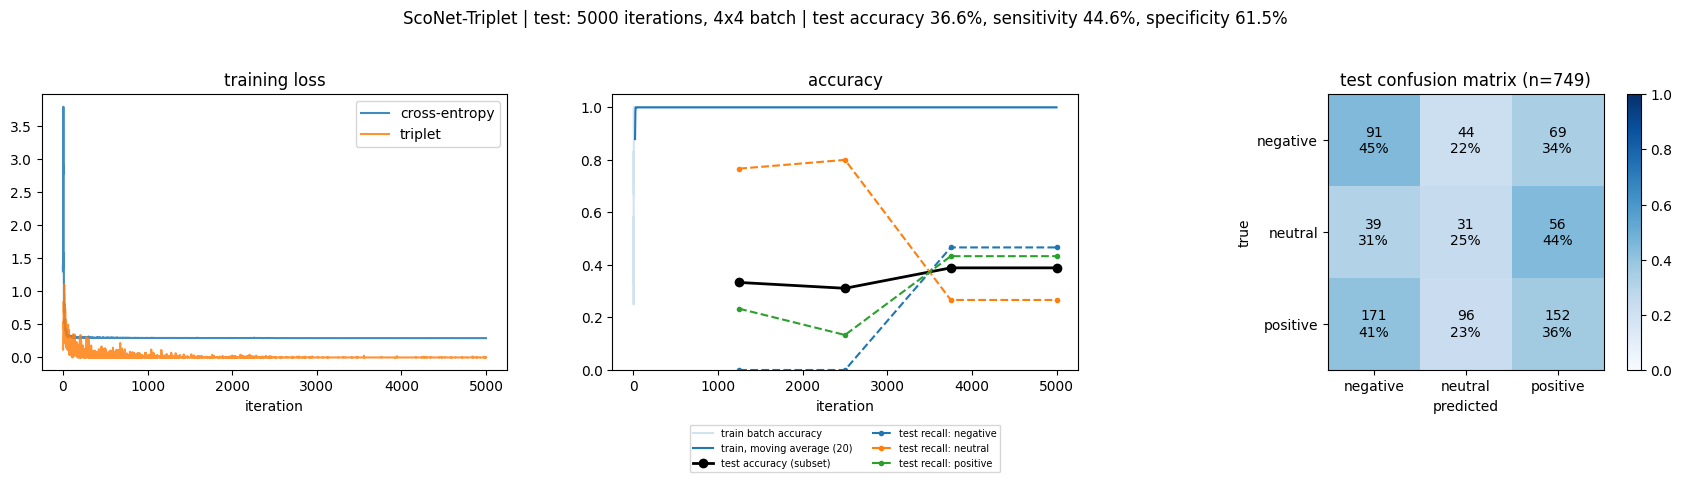

In [20]:
if not RUN_FULL:
    print("RUN_FULL is False -> skipping. Set it to True above to train on the partition.")
else:
    # ---------- data ----------
    with open(PARTITION_JSON, "r", encoding="utf-8") as f:
        partition = json.load(f)

    train_items = build_index(DATASET_ROOT, partition["TRAIN_SET"])
    test_items = build_index(DATASET_ROOT, partition["TEST_SET"])

    print("Training samples:", len(train_items))
    print("Class counts:", class_counts(train_items))

    check_split(train_items, test_items)

    if ONE_PER_CLASS:
        train_items = select_one_per_class(train_items)
        print("\nONE_PER_CLASS: training on only " + str(len(train_items)) + " sequences (the first of each class): "
              + ", ".join(f"{LABELS[c]} (subject {sid})" for sid, c, _ in train_items))
    ids_in_batch = min(IDS_PER_BATCH, len({sid for sid, _, _ in train_items}))      # fewer subjects than IDS_PER_BATCH -> smaller batch

    if DEVICE.type == "cuda":
        print(f"\nGPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB) | float16: {USE_AMP}")
    print(f"{MODEL_VARIANT} | profile '{PROFILE}': {TOTAL_ITERS} iterations, {ids_in_batch} ids x {SEQS_PER_ID} clips "
          f"= {ids_in_batch * SEQS_PER_ID} sequences per iteration\n")

    # ---------- training (in chunks, with a quick test-subset check after each chunk) ----------
    set_seed()                                       # same start every time, whatever cells ran before
    eval_subset = make_eval_subset(test_items)
    triplet_on = TRIPLET_ON[MODEL_VARIANT]
    full_model = make_model()
    get_batch = make_triplet_batch_fn(train_items, IDS_PER_BATCH, SEQS_PER_ID)
    history_full, eval_iters, eval_acc, eval_recall = train_with_periodic_eval(full_model, get_batch, eval_subset, triplet_on)

    # ---------- final evaluation on the whole test set ----------
    print("Evaluating on the whole TEST_SET ...")
    conf = confusion(full_model, test_items)
    accuracy, sensitivity, specificity = paper_metrics(conf)
    paper = ""
    if SPLIT_KEY in PAPER_ACC:
        paper = f" | paper, split {SPLIT_KEY}: ScoNet {PAPER_ACC[SPLIT_KEY][0]}%, ScoNet-MT {PAPER_ACC[SPLIT_KEY][1]}%"
    print(f"accuracy {accuracy:.1%} | sensitivity {sensitivity:.1%} | specificity {specificity:.1%}{paper}")
    macro_p, macro_r, macro_f1 = macro_metrics(conf)
    print(f"macro precision {macro_p:.1%} | macro recall {macro_r:.1%} | macro F1 {macro_f1:.1%}   (what OpenGait's evaluate_scoliosis logs)")

    plot_results(history_full, eval_iters, eval_acc, eval_recall, conf, triplet_on)

In [21]:
def recalibrated_copy(model, get_batch, n_batches=50):
    """Copy of the model whose BatchNorm running statistics are recomputed from training batches."""
    m2 = copy.deepcopy(model)
    for m in m2.modules():
        if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)):
            m.reset_running_stats()
            m.momentum = None                  # cumulative average over the batches below
    m2.train()
    with torch.no_grad():
        for _ in range(n_batches):
            sils, _, _ = get_batch()
            m2(torch.as_tensor(sils, dtype=torch.float32, device=DEVICE))
    return m2.eval()

m2 = recalibrated_copy(full_model, get_batch)
sub = confusion(m2, eval_subset)
print(sub, "\nsubset accuracy:", sub.trace() / sub.sum())

[[14  4 12]
 [ 8  6 16]
 [12  5 13]] 
subset accuracy: 0.36666666666666664


## Where to go from here

1. Parts 1 to 7: both sanity checks should pass (training PASS; eval 2/3 or 3/3 is fine, the full videos differ from the 30-frame clips used in training).
2. Part 8 with `PROFILE = "quick"` (200 iterations, 4 x 4 batch). Read the split check first: your class counts should match the paper's for the same split.
3. Compare with the paper's numbers for that split. Do not expect the paper's numbers from 200 iterations; `quick` only checks the pipeline and the split. Use `scaled` or `paper` for a real comparison.
4. For a faithful reproduction, run `PROFILE = "paper"` (20,000 iterations, 8 x 8 batch) on a GPU that can finish it. `MODEL_VARIANT = "ScoNet-MT"` is what the official YAML trains (paper: 82.0%); `"ScoNet"` (cross-entropy only) is the paper's plain ScoNet row (51.3%) and shows the imbalance effect.
5. Compare this model with the OpenGait version on the same inputs (load the same weights into both and check the logits match).